In [5]:

import os
from pathlib import Path

# Set Jupyter's working directory
os.chdir(
    r"C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\notebooks"
)

# Confirm the working directory
print("Current working directory:", Path.cwd())

# Set project paths
ROOT = Path.cwd().resolve().parent
results_folder = ROOT / "results"
figures_folder = ROOT / "figures"

print("Project root:", ROOT)

# Verify our saved data
for filename in [
    "arxiv_paper_topics.csv",
    "arxiv_influence_results.csv",
    "arxiv_louvain_membership.csv"
]:
    path = results_folder / filename
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {filename}")


Current working directory: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\notebooks
Project root: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis
FOUND: arxiv_paper_topics.csv
FOUND: arxiv_influence_results.csv
FOUND: arxiv_louvain_membership.csv


In [6]:

# Step 8.2A — Inspect saved NLP topics and network influence data

from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve().parent

results_folder = ROOT / "results"
figures_folder = ROOT / "figures"

topic_path = results_folder / "arxiv_paper_topics.csv"
influence_path = results_folder / "arxiv_influence_results.csv"
membership_path = results_folder / "arxiv_louvain_membership.csv"

# Confirm all files exist
for path in [topic_path, influence_path, membership_path]:
    assert path.exists(), f"Missing file: {path.name}"

# Load existing results
topics_df = pd.read_csv(topic_path)
influence_df = pd.read_csv(influence_path)
membership_df = pd.read_csv(membership_path)

print("TOPIC-AWARE DIFFUSION: DATA VALIDATION")
print("-" * 60)

for name, df in [
    ("Topics", topics_df),
    ("Influence", influence_df),
    ("Community membership", membership_df)
]:
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Unique nodes:", df["node idx"].nunique())
    print("Duplicate nodes:", df["node idx"].duplicated().sum())

# Check that all three datasets describe the same nodes
topic_nodes = set(topics_df["node idx"])
influence_nodes = set(influence_df["node idx"])
community_nodes = set(membership_df["node idx"])

print("\nNODE ALIGNMENT")
print("-" * 60)
print("Topics vs influence:", topic_nodes == influence_nodes)
print("Topics vs communities:", topic_nodes == community_nodes)

print("\nTOPIC DISTRIBUTION")
print("-" * 60)

display(
    topics_df["topic_label"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Number of papers")
)

print("\nTOPIC DATA PREVIEW")
display(
    topics_df[
        ["node idx", "title", "dominant_topic",
         "topic_label", "topic_strength"]
    ].head()
)


TOPIC-AWARE DIFFUSION: DATA VALIDATION
------------------------------------------------------------

Topics
Shape: (5000, 18)
Columns: ['node idx', 'paper id', 'title', 'dominant_topic', 'topic_strength', 'topic_label', 'topic_0_weight', 'topic_1_weight', 'topic_2_weight', 'topic_3_weight', 'topic_4_weight', 'topic_5_weight', 'topic_6_weight', 'topic_7_weight', 'topic_8_weight', 'topic_9_weight', 'topic_10_weight', 'topic_11_weight']
Unique nodes: 5000
Duplicate nodes: 0

Influence
Shape: (5000, 8)
Columns: ['node idx', 'degree_centrality', 'in_degree', 'out_degree', 'pagerank', 'paper id', 'title', 'betweenness']
Unique nodes: 5000
Duplicate nodes: 0

Community membership
Shape: (5000, 2)
Columns: ['node idx', 'louvain_community']
Unique nodes: 5000
Duplicate nodes: 0

NODE ALIGNMENT
------------------------------------------------------------
Topics vs influence: True
Topics vs communities: True

TOPIC DISTRIBUTION
------------------------------------------------------------


,Topic,Number of papers
0,Differential Privacy,704
1,Theoretical Bounds and Complexity,607
2,Federated Learning,588
3,Multi-Armed Bandits and Regret,490
4,Subspace Clustering,457
5,Convex and Stochastic Optimization,408
6,Compressed Sensing and Sparse Recovery,359
7,Deep Learning and Neural Networks,337
8,Matrix Decomposition and Low-Rank Methods,295
9,Community Detection,284



TOPIC DATA PREVIEW


,node idx,title,dominant_topic,topic_label,topic_strength
0,0,evasion attacks against machine learning at te...,11,Adversarial Machine Learning,0.141397
1,31,learning transformations for clustering and cl...,9,Subspace Clustering,0.186696
2,65,improved analysis for subspace pursuit algorit...,4,Compressed Sensing and Sparse Recovery,0.190195
3,112,rappor randomized aggregatable privacy preserv...,1,Differential Privacy,0.091500
4,148,efficient synthesis of network updates,5,Community Detection,0.042273


In [7]:

# Step 8.2B — Combine topic, influence and community data

import numpy as np
import pandas as pd

# Keep one copy of the paper metadata
topic_influence_df = (
    topics_df
    .merge(
        influence_df.drop(columns=["paper id", "title"]),
        on="node idx",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        membership_df,
        on="node idx",
        how="inner",
        validate="one_to_one"
    )
)

# Identify the 12 NMF topic-weight columns
topic_weight_cols = [
    f"topic_{i}_weight"
    for i in range(12)
]

# Validate the merged dataset
assert len(topic_influence_df) == 5000
assert topic_influence_df["node idx"].is_unique
assert topic_influence_df[topic_weight_cols].notna().all().all()
assert (
    topic_influence_df[topic_weight_cols] >= 0
).all().all()

# Check that dominant-topic assignments match topic weights
dominant_from_weights = (
    topic_influence_df[topic_weight_cols]
    .to_numpy()
    .argmax(axis=1)
)

agreement = np.mean(
    dominant_from_weights ==
    topic_influence_df["dominant_topic"].to_numpy()
)

print("TOPIC-INFLUENCE DATA VALIDATION")
print("-" * 60)
print("Merged shape:", topic_influence_df.shape)
print("Unique nodes:", topic_influence_df["node idx"].nunique())
print("Topic-weight columns:", len(topic_weight_cols))
print(f"Dominant-topic agreement: {agreement:.2%}")

print("\nTOPIC WEIGHT STATISTICS")
display(
    topic_influence_df[
        ["topic_strength", "pagerank", "degree_centrality"]
    ].describe().round(4)
)

print("\nMERGED DATA PREVIEW")
display(
    topic_influence_df[
        [
            "node idx",
            "topic_label",
            "topic_strength",
            "pagerank",
            "degree_centrality",
            "louvain_community"
        ]
    ].head()
)


TOPIC-INFLUENCE DATA VALIDATION
------------------------------------------------------------
Merged shape: (5000, 24)
Unique nodes: 5000
Topic-weight columns: 12
Dominant-topic agreement: 100.00%

TOPIC WEIGHT STATISTICS


,topic_strength,pagerank,degree_centrality
count,5000.0000,5000.0000,5000.0000
mean,0.0881,0.0002,0.0022
std,0.0387,0.0009,0.0041
min,0.0063,0.0001,0.0002
25%,0.0586,0.0001,0.0006
50%,0.0826,0.0001,0.0012
75%,0.1122,0.0001,0.0024
max,0.2375,0.0221,0.1124



MERGED DATA PREVIEW


,node idx,topic_label,topic_strength,pagerank,degree_centrality,louvain_community
0,0,Adversarial Machine Learning,0.141397,0.001001,0.013403,13
1,31,Subspace Clustering,0.186696,0.000075,0.001200,8
2,65,Compressed Sensing and Sparse Recovery,0.190195,0.000070,0.001600,12
3,112,Differential Privacy,0.091500,0.001783,0.036207,3
4,148,Community Detection,0.042273,0.000070,0.000200,3


In [8]:

# Step 8.2C — Examine topic size and network influence

topic_profile_df = (
    topic_influence_df
    .groupby(["dominant_topic", "topic_label"])
    .agg(
        paper_count=("node idx", "count"),
        mean_pagerank=("pagerank", "mean"),
        median_pagerank=("pagerank", "median"),
        max_pagerank=("pagerank", "max"),
        mean_degree=("degree_centrality", "mean"),
        mean_topic_strength=("topic_strength", "mean"),
        communities_represented=("louvain_community", "nunique")
    )
    .reset_index()
    .sort_values("paper_count", ascending=False)
)

print("TOPIC PROFILES")
print("-" * 70)

display(
    topic_profile_df[
        [
            "dominant_topic",
            "topic_label",
            "paper_count",
            "mean_pagerank",
            "max_pagerank",
            "mean_degree",
            "communities_represented"
        ]
    ].round(6)
)

print("\nTOPIC SIZE RANGE")
print(
    "Smallest:",
    topic_profile_df["paper_count"].min(),
    "papers"
)
print(
    "Largest:",
    topic_profile_df["paper_count"].max(),
    "papers"
)

print("\nTOPICS WITH HIGHEST MEAN PAGERANK")
display(
    topic_profile_df.nlargest(
        5, "mean_pagerank"
    )[
        [
            "topic_label",
            "paper_count",
            "mean_pagerank",
            "communities_represented"
        ]
    ].round(6)
)


TOPIC PROFILES
----------------------------------------------------------------------


,dominant_topic,topic_label,paper_count,mean_pagerank,max_pagerank,mean_degree,communities_represented
1,1,Differential Privacy,704,0.000256,0.019557,0.002944,12
2,2,Theoretical Bounds and Complexity,607,0.000186,0.006536,0.002054,14
8,8,Federated Learning,588,0.000097,0.002181,0.001851,14
3,3,Multi-Armed Bandits and Regret,490,0.000161,0.010519,0.001751,9
9,9,Subspace Clustering,457,0.000140,0.020075,0.001400,13
7,7,Convex and Stochastic Optimization,408,0.000198,0.005630,0.001656,14
4,4,Compressed Sensing and Sparse Recovery,359,0.000313,0.022140,0.001704,12
6,6,Deep Learning and Neural Networks,337,0.000246,0.010770,0.002841,13
10,10,Matrix Decomposition and Low-Rank Methods,295,0.000369,0.011556,0.003134,11
5,5,Community Detection,284,0.000155,0.008623,0.000937,14



TOPIC SIZE RANGE
Smallest: 207 papers
Largest: 704 papers

TOPICS WITH HIGHEST MEAN PAGERANK


,topic_label,paper_count,mean_pagerank,communities_represented
10,Matrix Decomposition and Low-Rank Methods,295,0.000369,11
4,Compressed Sensing and Sparse Recovery,359,0.000313,12
1,Differential Privacy,704,0.000256,12
6,Deep Learning and Neural Networks,337,0.000246,13
0,Graph Theory and Spectral Methods,207,0.000221,8


In [9]:

# Step 8.2D — Generate topic-aware seed-selection strategies

import numpy as np
import pandas as pd

seed_budget = 10
topic_seed_records = []

# PageRank percentile across all 5,000 papers
topic_influence_df["pagerank_percentile"] = (
    topic_influence_df["pagerank"]
    .rank(pct=True, method="average")
)

for topic_id in range(12):

    topic_col = f"topic_{topic_id}_weight"

    # Topic relevance percentile
    topic_percentile = (
        topic_influence_df[topic_col]
        .rank(pct=True, method="average")
    )

    # Equal-weight combination
    combined_score = (
        0.5 * topic_influence_df["pagerank_percentile"]
        + 0.5 * topic_percentile
    )

    # Create a temporary ranking table
    ranking_df = topic_influence_df[
        ["node idx", "title", "pagerank", "louvain_community"]
    ].copy()

    ranking_df["topic_id"] = topic_id
    ranking_df["topic_weight"] = topic_influence_df[topic_col]
    ranking_df["topic_percentile"] = topic_percentile
    ranking_df["combined_score"] = combined_score

    strategies = {
        "PageRank-only": ranking_df.nlargest(
            seed_budget, "pagerank"
        ),
        "Topic-only": ranking_df.nlargest(
            seed_budget, "topic_weight"
        ),
        "Topic-aware PageRank": ranking_df.nlargest(
            seed_budget, "combined_score"
        )
    }

    for strategy, selected in strategies.items():

        for rank, (_, paper) in enumerate(
            selected.iterrows(), start=1
        ):
            topic_seed_records.append({
                "topic_id": topic_id,
                "strategy": strategy,
                "seed_rank": rank,
                "node idx": int(paper["node idx"]),
                "title": paper["title"],
                "pagerank": paper["pagerank"],
                "topic_weight": paper["topic_weight"],
                "combined_score": paper["combined_score"],
                "louvain_community": paper["louvain_community"]
            })

topic_seed_df = pd.DataFrame(topic_seed_records)

# Validate seed selection
assert len(topic_seed_df) == 12 * 3 * seed_budget

assert (
    topic_seed_df
    .groupby(["topic_id", "strategy"])["node idx"]
    .nunique()
    .eq(seed_budget)
    .all()
)

print("TOPIC-AWARE SEED SELECTION")
print("-" * 60)
print("Topics:", topic_seed_df["topic_id"].nunique())
print("Strategies:", topic_seed_df["strategy"].nunique())
print("Seeds per strategy:", seed_budget)
print("Total seed records:", len(topic_seed_df))

# Examine how different the strategies are
seed_overlap_records = []

for topic_id in range(12):

    topic_data = topic_seed_df[
        topic_seed_df["topic_id"] == topic_id
    ]

    pagerank_seeds = set(
        topic_data.loc[
            topic_data["strategy"] == "PageRank-only",
            "node idx"
        ]
    )

    for strategy in ["Topic-only", "Topic-aware PageRank"]:

        comparison_seeds = set(
            topic_data.loc[
                topic_data["strategy"] == strategy,
                "node idx"
            ]
        )

        seed_overlap_records.append({
            "topic_id": topic_id,
            "comparison": strategy,
            "overlap_with_pagerank": len(
                pagerank_seeds & comparison_seeds
            )
        })

seed_overlap_df = pd.DataFrame(seed_overlap_records)

print("\nSEED OVERLAP WITH PAGERANK")
display(
    seed_overlap_df.pivot(
        index="topic_id",
        columns="comparison",
        values="overlap_with_pagerank"
    )
)

# Save results
topic_seed_df.to_csv(
    results_folder / "arxiv_topic_aware_seed_selection.csv",
    index=False
)

seed_overlap_df.to_csv(
    results_folder / "arxiv_topic_seed_overlap.csv",
    index=False
)

print("\nSeed-selection results saved successfully.")


TOPIC-AWARE SEED SELECTION
------------------------------------------------------------
Topics: 12
Strategies: 3
Seeds per strategy: 10
Total seed records: 360

SEED OVERLAP WITH PAGERANK


comparison,Topic-aware PageRank,Topic-only
topic_id,,
0,0,0
1,2,0
2,0,0
3,1,0
4,3,0
5,0,0
6,1,0
7,0,0
8,0,0



Seed-selection results saved successfully.


In [10]:

# Step 8.2E — Restore the arXiv knowledge-flow graph

import os
import networkx as nx
import numpy as np
from ogb.nodeproppred import NodePropPredDataset

# Compatibility with previously downloaded OGB data
# Only use for trusted local dataset files
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

# Load original citation dataset
dataset = NodePropPredDataset(
    name="ogbn-arxiv",
    root=str(ROOT / "data" / "ogbn_arxiv")
)

graph_data, labels = dataset[0]

# Reconstruct the original directed citation graph
edge_index = graph_data["edge_index"]

G_full = nx.DiGraph()
G_full.add_nodes_from(range(graph_data["num_nodes"]))
G_full.add_edges_from(edge_index.T.tolist())

# Restore the exact 5,000 nodes used previously
subset_nodes = pd.read_csv(
    results_folder / "arxiv_subset_node_ids.csv"
)["node idx"].astype(int).tolist()

G_directed = G_full.subgraph(subset_nodes).copy()

# Reverse citations to represent knowledge flow
G_diffusion = G_directed.reverse(copy=True)

# Validate graph
assert G_diffusion.number_of_nodes() == 5000
assert G_diffusion.number_of_edges() == 27284

assert set(G_diffusion.nodes()) == set(
    topic_influence_df["node idx"]
)

print("ARXIV DIFFUSION GRAPH RESTORED")
print("-" * 55)
print("Nodes:", G_diffusion.number_of_nodes())
print("Directed edges:", G_diffusion.number_of_edges())
print("Topic-data alignment:", True)
print("Graph ready for topic-aware diffusion.")


C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\.venv\Lib\site-packages\ogb\nodeproppred\dataset.py:70: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  loaded_dict = torch.load(pre_processed_file_path)


ARXIV DIFFUSION GRAPH RESTORED
-------------------------------------------------------
Nodes: 5000
Directed edges: 27284
Topic-data alignment: True
Graph ready for topic-aware diffusion.


In [11]:

# Step 8.2F — Independent Cascade simulation

import numpy as np

def independent_cascade(graph, seeds, p=0.10, random_seed=42):
    rng = np.random.default_rng(random_seed)

    active = set(seeds)
    newly_active = set(seeds)
    activation_history = [len(active)]

    while newly_active:
        next_active = set()

        for source in sorted(newly_active):
            for target in sorted(graph.successors(source)):

                if target not in active and target not in next_active:
                    if rng.random() < p:
                        next_active.add(target)

        if not next_active:
            break

        active.update(next_active)
        newly_active = next_active
        activation_history.append(len(active))

    return {
        "total_spread": len(active),
        "rounds": len(activation_history) - 1,
        "activated_nodes": active,
        "activation_history": activation_history
    }


# Validate using a previously studied influential paper
test_seed = [47283]

test_result = independent_cascade(
    G_diffusion,
    seeds=test_seed,
    p=0.10,
    random_seed=42
)

# Boundary tests
zero_result = independent_cascade(
    G_diffusion, test_seed, p=0.0, random_seed=42
)

full_result = independent_cascade(
    G_diffusion, test_seed, p=1.0, random_seed=42
)

expected_full_spread = (
    len(nx.descendants(G_diffusion, test_seed[0])) + 1
)

assert zero_result["total_spread"] == 1
assert full_result["total_spread"] == expected_full_spread
assert test_result["total_spread"] >= 1

# Reproducibility test
repeat_result = independent_cascade(
    G_diffusion, test_seed, p=0.10, random_seed=42
)

assert (
    test_result["activated_nodes"]
    == repeat_result["activated_nodes"]
)

print("INDEPENDENT CASCADE VALIDATION")
print("-" * 55)
print("Test seed:", test_seed[0])
print("Spread at p=0:", zero_result["total_spread"])
print("Spread at p=0.10:", test_result["total_spread"])
print("Spread at p=1:", full_result["total_spread"])
print("Expected p=1 spread:", expected_full_spread)
print("Activation rounds:", test_result["rounds"])
print("Reproducibility: PASSED")
print("IC model ready for topic-aware experiments.")


INDEPENDENT CASCADE VALIDATION
-------------------------------------------------------
Test seed: 47283
Spread at p=0: 1
Spread at p=0.10: 60
Spread at p=1: 2457
Expected p=1 spread: 2457
Activation rounds: 4
Reproducibility: PASSED
IC model ready for topic-aware experiments.


In [12]:

# Step 8.2G — Pilot experiment: Differential Privacy

import time

target_topic = 1
n_simulations = 100
activation_probability = 0.10

topic_lookup = topic_influence_df.set_index(
    "node idx"
)["dominant_topic"].to_dict()

target_nodes = {
    node for node, topic in topic_lookup.items()
    if topic == target_topic
}

pilot_records = []
start_time = time.perf_counter()

for strategy in [
    "PageRank-only",
    "Topic-only",
    "Topic-aware PageRank"
]:

    seeds = (
        topic_seed_df.loc[
            (topic_seed_df["topic_id"] == target_topic)
            & (topic_seed_df["strategy"] == strategy)
        ]
        .sort_values("seed_rank")["node idx"]
        .astype(int)
        .tolist()
    )

    initial_target_seeds = len(set(seeds) & target_nodes)

    for sim_id in range(n_simulations):

        result = independent_cascade(
            G_diffusion,
            seeds=seeds,
            p=activation_probability,
            random_seed=42 + sim_id
        )

        activated = result["activated_nodes"]
        target_activated = len(activated & target_nodes)

        pilot_records.append({
            "topic_id": target_topic,
            "strategy": strategy,
            "simulation_id": sim_id,
            "total_spread": result["total_spread"],
            "target_topic_activated": target_activated,
            "initial_target_seeds": initial_target_seeds,
            "additional_target_activated": (
                target_activated - initial_target_seeds
            ),
            "target_topic_coverage_pct": (
                100 * target_activated / len(target_nodes)
            )
        })

pilot_df = pd.DataFrame(pilot_records)

pilot_summary = (
    pilot_df
    .groupby("strategy")
    .agg(
        mean_total_spread=("total_spread", "mean"),
        mean_target_activated=("target_topic_activated", "mean"),
        initial_target_seeds=("initial_target_seeds", "first"),
        mean_additional_target=("additional_target_activated", "mean"),
        mean_target_coverage_pct=("target_topic_coverage_pct", "mean"),
        std_target_activated=("target_topic_activated", "std")
    )
    .round(2)
)

print("DIFFERENTIAL PRIVACY: TOPIC-AWARE DIFFUSION")
print("-" * 65)
print("Target-topic papers:", len(target_nodes))
print("Simulations per strategy:", n_simulations)
print("Activation probability:", activation_probability)
print(f"Runtime: {time.perf_counter() - start_time:.2f} seconds")

display(pilot_summary)

pilot_df.to_csv(
    results_folder / "arxiv_topic_diffusion_pilot.csv",
    index=False
)

print("\nPilot simulation results saved.")


DIFFERENTIAL PRIVACY: TOPIC-AWARE DIFFUSION
-----------------------------------------------------------------
Target-topic papers: 704
Simulations per strategy: 100
Activation probability: 0.1
Runtime: 0.73 seconds


,mean_total_spread,mean_target_activated,initial_target_seeds,mean_additional_target,mean_target_coverage_pct,std_target_activated
strategy,,,,,,
PageRank-only,446.74,126.65,3,123.65,17.99,19.91
Topic-aware PageRank,230.16,146.64,10,136.64,20.83,18.23
Topic-only,40.58,31.70,10,21.70,4.50,17.71



Pilot simulation results saved.


In [13]:

# Step 8.2H — Topic-specific diffusion across all 12 topics

import time

n_simulations = 100
activation_probability = 0.10

all_topic_records = []
start_time = time.perf_counter()

strategies = [
    "PageRank-only",
    "Topic-only",
    "Topic-aware PageRank"
]

for topic_id in range(12):

    target_nodes = {
        node for node, topic in topic_lookup.items()
        if topic == topic_id
    }

    topic_name = topic_influence_df.loc[
        topic_influence_df["dominant_topic"] == topic_id,
        "topic_label"
    ].iloc[0]

    for strategy in strategies:

        seeds = (
            topic_seed_df.loc[
                (topic_seed_df["topic_id"] == topic_id)
                & (topic_seed_df["strategy"] == strategy)
            ]
            .sort_values("seed_rank")["node idx"]
            .astype(int)
            .tolist()
        )

        initial_target_seeds = len(
            set(seeds) & target_nodes
        )

        for sim_id in range(n_simulations):

            result = independent_cascade(
                G_diffusion,
                seeds=seeds,
                p=activation_probability,
                random_seed=42 + sim_id
            )

            activated = result["activated_nodes"]

            target_activated = len(
                activated & target_nodes
            )

            all_topic_records.append({
                "topic_id": topic_id,
                "topic_label": topic_name,
                "strategy": strategy,
                "simulation_id": sim_id,
                "total_spread": result["total_spread"],
                "target_topic_activated": target_activated,
                "initial_target_seeds": initial_target_seeds,
                "additional_target_activated": (
                    target_activated - initial_target_seeds
                ),
                "target_topic_coverage_pct": (
                    100 * target_activated / len(target_nodes)
                )
            })

    print(f"Completed topic {topic_id}: {topic_name}")

all_topic_df = pd.DataFrame(all_topic_records)

assert len(all_topic_df) == 3600

# Summarise each topic and strategy
all_topic_summary = (
    all_topic_df
    .groupby(
        ["topic_id", "topic_label", "strategy"],
        as_index=False
    )
    .agg(
        mean_total_spread=("total_spread", "mean"),
        mean_target_activated=("target_topic_activated", "mean"),
        mean_additional_target=("additional_target_activated", "mean"),
        mean_target_coverage_pct=("target_topic_coverage_pct", "mean")
    )
)

# Compare topic-aware PageRank against PageRank-only
coverage_comparison = (
    all_topic_summary
    .pivot(
        index=["topic_id", "topic_label"],
        columns="strategy",
        values="mean_target_coverage_pct"
    )
    .reset_index()
)

coverage_comparison["topic_aware_gain_pp"] = (
    coverage_comparison["Topic-aware PageRank"]
    - coverage_comparison["PageRank-only"]
)

print("\nALL-TOPIC DIFFUSION SUMMARY")
print("-" * 70)
print("Total simulations:", len(all_topic_df))
print(
    f"Runtime: {time.perf_counter() - start_time:.2f} seconds"
)

display(
    coverage_comparison.round(2)
)

print("\nTOPICS WHERE TOPIC-AWARE PAGERANK WINS:")
print(
    (
        coverage_comparison["topic_aware_gain_pp"] > 0
    ).sum(),
    "out of 12"
)

# Save results
all_topic_df.to_csv(
    results_folder / "arxiv_topic_diffusion_simulations.csv",
    index=False
)

all_topic_summary.to_csv(
    results_folder / "arxiv_topic_diffusion_summary.csv",
    index=False
)

coverage_comparison.to_csv(
    results_folder / "arxiv_topic_diffusion_comparison.csv",
    index=False
)

print("\nAll-topic diffusion results saved.")


Completed topic 0: Graph Theory and Spectral Methods
Completed topic 1: Differential Privacy
Completed topic 2: Theoretical Bounds and Complexity
Completed topic 3: Multi-Armed Bandits and Regret
Completed topic 4: Compressed Sensing and Sparse Recovery
Completed topic 5: Community Detection
Completed topic 6: Deep Learning and Neural Networks
Completed topic 7: Convex and Stochastic Optimization
Completed topic 8: Federated Learning
Completed topic 9: Subspace Clustering
Completed topic 10: Matrix Decomposition and Low-Rank Methods
Completed topic 11: Adversarial Machine Learning

ALL-TOPIC DIFFUSION SUMMARY
----------------------------------------------------------------------
Total simulations: 3600
Runtime: 7.90 seconds


strategy,topic_id,topic_label,PageRank-only,Topic-aware PageRank,Topic-only,topic_aware_gain_pp
0,0,Graph Theory and Spectral Methods,5.87,19.65,11.71,13.78
1,1,Differential Privacy,17.99,20.83,4.50,2.84
2,2,Theoretical Bounds and Complexity,6.00,6.23,2.99,0.23
3,3,Multi-Armed Bandits and Regret,9.21,18.26,7.09,9.05
4,4,Compressed Sensing and Sparse Recovery,12.81,18.54,5.67,5.73
5,5,Community Detection,5.54,10.26,3.55,4.73
6,6,Deep Learning and Neural Networks,6.76,18.79,4.02,12.03
7,7,Convex and Stochastic Optimization,6.08,10.81,5.82,4.73
8,8,Federated Learning,6.19,9.40,3.49,3.22
9,9,Subspace Clustering,8.31,11.79,3.88,3.47



TOPICS WHERE TOPIC-AWARE PAGERANK WINS:
12 out of 12

All-topic diffusion results saved.


In [14]:

# Step 8.2I — Bootstrap confidence intervals for topic-aware gains

import numpy as np
import pandas as pd

n_bootstrap = 10000
rng = np.random.default_rng(42)

bootstrap_records = []

for topic_id in range(12):

    topic_data = all_topic_df[
        all_topic_df["topic_id"] == topic_id
    ]

    comparison = topic_data.pivot(
        index="simulation_id",
        columns="strategy",
        values="target_topic_coverage_pct"
    )

    # Difference for each matched simulation ID
    differences = (
        comparison["Topic-aware PageRank"]
        - comparison["PageRank-only"]
    ).to_numpy()

    observed_gain = differences.mean()

    # Bootstrap the mean difference
    bootstrap_indices = rng.integers(
        low=0,
        high=len(differences),
        size=(n_bootstrap, len(differences))
    )

    bootstrap_means = (
        differences[bootstrap_indices].mean(axis=1)
    )

    ci_lower, ci_upper = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    topic_name = topic_data["topic_label"].iloc[0]

    bootstrap_records.append({
        "topic_id": topic_id,
        "topic_label": topic_name,
        "mean_gain_pp": observed_gain,
        "ci_lower_pp": ci_lower,
        "ci_upper_pp": ci_upper,
        "ci_excludes_zero": ci_lower > 0 or ci_upper < 0
    })

bootstrap_df = pd.DataFrame(bootstrap_records)

print("TOPIC-AWARE DIFFUSION: BOOTSTRAP RESULTS")
print("-" * 70)
print("Bootstrap resamples:", n_bootstrap)
print("Confidence level: 95%")

display(
    bootstrap_df[
        [
            "topic_id",
            "topic_label",
            "mean_gain_pp",
            "ci_lower_pp",
            "ci_upper_pp",
            "ci_excludes_zero"
        ]
    ].round(2)
)

print("\nTOPICS WITH CONFIDENCE INTERVALS ABOVE ZERO:")
print(
    (bootstrap_df["ci_lower_pp"] > 0).sum(),
    "out of 12"
)

bootstrap_df.to_csv(
    results_folder / "arxiv_topic_diffusion_bootstrap.csv",
    index=False
)

print("\nBootstrap results saved.")


TOPIC-AWARE DIFFUSION: BOOTSTRAP RESULTS
----------------------------------------------------------------------
Bootstrap resamples: 10000
Confidence level: 95%


,topic_id,topic_label,mean_gain_pp,ci_lower_pp,ci_upper_pp,ci_excludes_zero
0,0,Graph Theory and Spectral Methods,13.78,13.26,14.31,True
1,1,Differential Privacy,2.84,2.16,3.52,True
2,2,Theoretical Bounds and Complexity,0.23,-0.13,0.59,False
3,3,Multi-Armed Bandits and Regret,9.05,8.47,9.63,True
4,4,Compressed Sensing and Sparse Recovery,5.73,5.08,6.36,True
5,5,Community Detection,4.73,4.22,5.21,True
6,6,Deep Learning and Neural Networks,12.03,11.18,12.85,True
7,7,Convex and Stochastic Optimization,4.73,4.28,5.17,True
8,8,Federated Learning,3.22,2.82,3.61,True
9,9,Subspace Clustering,3.47,3.15,3.80,True



TOPICS WITH CONFIDENCE INTERVALS ABOVE ZERO:
11 out of 12

Bootstrap results saved.


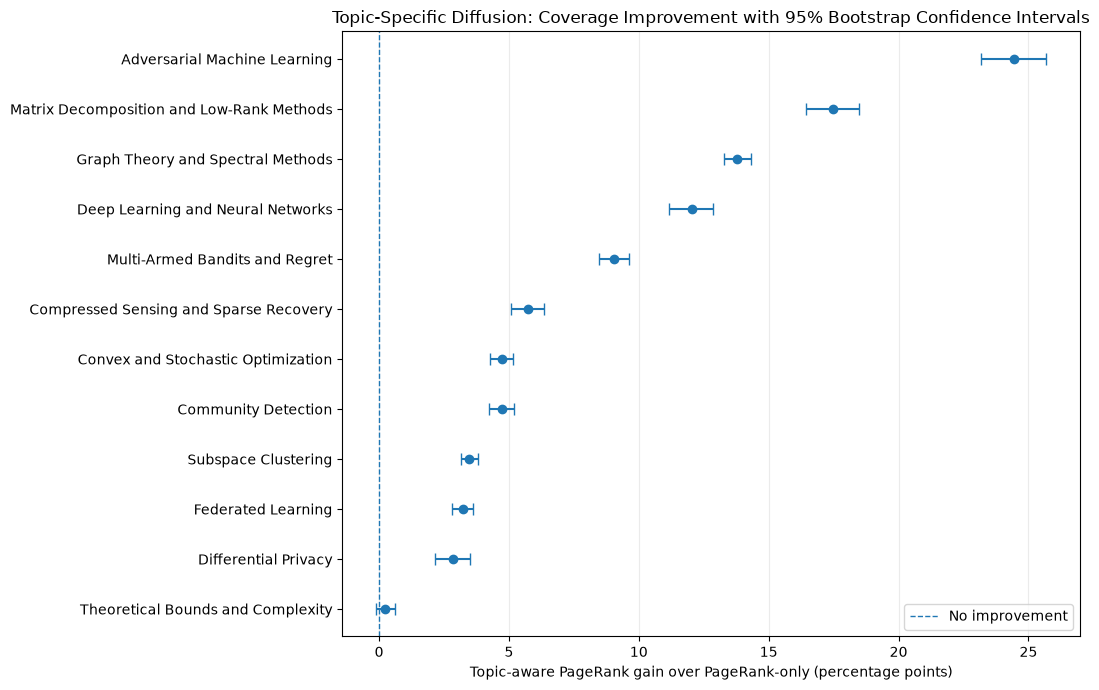

Figure saved to: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_topic_diffusion_gains.png


In [15]:

# Step 8.2J — Plot topic-aware coverage gains with confidence intervals

import matplotlib.pyplot as plt
import numpy as np

plot_df = bootstrap_df.sort_values(
    "mean_gain_pp", ascending=True
).copy()

y_positions = np.arange(len(plot_df))

lower_errors = (
    plot_df["mean_gain_pp"] - plot_df["ci_lower_pp"]
).to_numpy()

upper_errors = (
    plot_df["ci_upper_pp"] - plot_df["mean_gain_pp"]
).to_numpy()

fig, ax = plt.subplots(figsize=(11, 7))

ax.errorbar(
    plot_df["mean_gain_pp"],
    y_positions,
    xerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=4,
    markersize=6,
    linewidth=1.5
)

ax.axvline(
    x=0,
    linestyle="--",
    linewidth=1,
    label="No improvement"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(plot_df["topic_label"])

ax.set_xlabel(
    "Topic-aware PageRank gain over PageRank-only "
    "(percentage points)"
)

ax.set_title(
    "Topic-Specific Diffusion: Coverage Improvement "
    "with 95% Bootstrap Confidence Intervals"
)

ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()

figure_path = (
    figures_folder / "arxiv_topic_diffusion_gains.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)
